# 04c – Densité des professionnels de santé (Ameli 2024)

Source : [Assurance Maladie](https://www.assurance-maladie.ameli.fr/etudes-et-donnees/densite-professionnels-sante-liberaux-departement)

Limites :
- seuls les médecins libéraux sont comptés, pas ceux de l'hôpital
- la densité est calculée sur les habitants, les touristes ne sont pas comptés
- la densité des pédiatres est calculée sur les 0-19 ans

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Importation des données

In [2]:
fichier_ameli = pd.ExcelFile('../data/raw/Socio Eco/ameli_densite_2024.xls')
print(fichier_ameli.sheet_names)

ameli_gen = pd.read_excel(fichier_ameli, sheet_name='Généralistes et MEP')
ameli_spe = pd.read_excel(fichier_ameli, sheet_name='Spécialistes')
ameli_aux = pd.read_excel(fichier_ameli, sheet_name='Auxiliaires médicaux')

ameli_gen.head()

['Lisez moi', 'Nomenclature des PS', 'Spécialistes', 'Généralistes et MEP', 'Dentistes et ODF', 'Sages-femmes', 'Auxiliaires médicaux', 'Laboratoires', 'Psychologues']


,Généralistes et compétence MEP,DEPARTEMENT,EFFECTIF,POPULATION FRANCAISE,DENSITE /100 000 hab.
0,01- Médecine générale,01- Ain,368,688626,53.439748
1,01- Médecine générale,02- Aisne,311,518817,59.944065
2,01- Médecine générale,03- Allier,221,332599,66.446381
3,01- Médecine générale,04- Alpes-Hte-Provence,152,169806,89.513916
4,01- Médecine générale,05- Hautes-Alpes,178,142006,125.346816


Le fichier a 9 onglets. Je garde les 3 qui concernent les maladies respiratoires(les autres onglets n'ont rien à voir: Lisez moi, dentistes, sages-femmes...). Une ligne = une catégorie de professionnels dans un département.

## 2. Contrôle des données

In [3]:
onglets = [ameli_gen, ameli_spe, ameli_aux]
noms_onglets = ['Généralistes et MEP', 'Spécialistes', 'Auxiliaires médicaux']

for i in range(3):
    tableau = onglets[i]
    print("Onglet", noms_onglets[i])
    print("taille :", tableau.shape)
    print("colonnes :", list(tableau.columns))
    print(tableau.head(3))
    print("nombre de catégories :", tableau.iloc[:, 0].nunique())
    print("lignes par catégorie :", tableau.iloc[:, 0].value_counts().unique())
    print("cases vides :", tableau.isna().sum().sum())
    print("lignes en double :", tableau.duplicated().sum())
    print("----------------------------------------------------------------------------------")

# les lignes qui ne sont pas des départements
print(list(ameli_gen[ameli_gen['DEPARTEMENT'].str.contains('TOTAL')]['DEPARTEMENT'].unique()))

Onglet Généralistes et MEP
taille : (6968, 5)
colonnes : ['Généralistes et compétence MEP', 'DEPARTEMENT', 'EFFECTIF', 'POPULATION FRANCAISE', 'DENSITE /100 000 hab.']
  Généralistes et compétence MEP DEPARTEMENT  EFFECTIF  POPULATION FRANCAISE  \
0          01- Médecine générale     01- Ain       368                688626   
1          01- Médecine générale   02- Aisne       311                518817   
2          01- Médecine générale  03- Allier       221                332599   

   DENSITE /100 000 hab.  
0              53.439748  
1              59.944065  
2              66.446381  
nombre de catégories : 67
lignes par catégorie : [104]
cases vides : 0
lignes en double : 0
----------------------------------------------------------------------------------
Onglet Spécialistes
taille : (5928, 5)
colonnes : ['Spécialistes', 'DEPARTEMENT', 'EFFECTIF', 'POPULATION FRANCAISE', 'DENSITE /100 000 hab.']
                              Spécialistes DEPARTEMENT  EFFECTIF  \
0  02- Anesthésie

Pas de cases vides ni de lignes en double. Chaque catégorie a 104 lignes : 101 départements et 3 lignes de total (France métropolitaine, Outre-mer, France entière) que je retire. Certaines catégories sont aussi des totaux (TOTAL MEDECINS, OMNIPRATICIENS, MEP...). Je ne les utilise pas pour ne pas compter deux fois les mêmes médecins.

## 3. Choix des professions

In [4]:
recap_par_onglet = []  #liste vide, contiendra 3 tableaux (1 pour chaque onglet)

for i in range(3):
    tableau = onglets[i]
    # on enlève les lignes de total des départements
    departements = tableau[tableau['DEPARTEMENT'].str.contains('TOTAL') == False]
    categorie = tableau.columns[0] #récupère la case A1 (Spécialiste, Généraliste et MEP,ou Auxiliaires médicaux) 

    recap_onglet = pd.DataFrame()
    recap_onglet['nb_france'] = departements.groupby(categorie)['EFFECTIF'].sum()
    zero = departements[departements['EFFECTIF'] == 0]
    recap_onglet['nb_dep_sans_aucun'] = zero.groupby(categorie)['EFFECTIF'].count()
    recap_onglet['onglet'] = noms_onglets[i]
    recap_par_onglet.append(recap_onglet)

recap_ameli = pd.concat(recap_par_onglet)
recap_ameli = recap_ameli.fillna(0)
recap_ameli['nb_dep_sans_aucun'] = recap_ameli['nb_dep_sans_aucun'].astype(int)

# on enlève aussi les catégories qui sont des totaux (sommes d'autres catégories)
a_enlever = []   # OMNI = MG + MEP, et MEP = total des sous-catégories MEP : on les retire (double compte)
for nom in recap_ameli.index:
    if 'TOTAL' in nom or nom == '01- OMNIPRATICIENS' or nom == '01- M.E.P.':
        a_enlever.append(nom)
recap_ameli = recap_ameli.drop(a_enlever)  

# combien de catégories il reste, au total et par onglet
print("catégories enlevées :", a_enlever)
print("nombre de catégories :", len(recap_ameli))
print(recap_ameli['onglet'].value_counts())

# afficher en affichant par nb de professionels le plus nombreux
recap_ameli.sort_values(['onglet', 'nb_france'], ascending=[True, False])

catégories enlevées : ['01- M.E.P.', '01- OMNIPRATICIENS', 'TOTAL ANESTHESIE REANIMATION  (02, 20)', 'TOTAL CHIRURGIE  (43, 44, 46, 47, 48, 49, 04, 10,16 ,41)', 'TOTAL GYNECOLOGIE  (70, 77, 79, 07)', 'TOTAL MEDECINE INTERNE  (71, 73, 09)', 'TOTAL MEDECINS', 'TOTAL PEDIATRIE  (78, 12)', 'TOTAL PSYCHIATRIE  (75, 33,17)', 'TOTAL RADIOLOGIE  (72, 74, 76, 06)', 'TOTAL SPECIALISTES', 'TOTAL STOMATOLOGIE  (69, 45, 18)', 'TOTAL AUXILIAIRES MEDICAUX']
nombre de catégories : 118
onglet
Généralistes et MEP     65
Spécialistes            47
Auxiliaires médicaux     6
Name: count, dtype: int64


,nb_france,nb_dep_sans_aucun,onglet
24- Infirmiers,98628,0,Auxiliaires médicaux
26- Masseurs-kinésithérapeutes-rééducateurs,82101,0,Auxiliaires médicaux
28- Orthophonistes,21763,0,Auxiliaires médicaux
27- Pédicures,13025,0,Auxiliaires médicaux
29- Orthoptistes,3245,0,Auxiliaires médicaux
...,...,...,...
20- Réanimation médicale,47,82,Spécialistes
81-Maladies infectieuses et tropicales,16,88,Spécialistes
78- Médecine génétique,8,95,Spécialistes
77- Obstétrique,5,97,Spécialistes


Pour chaque catégorie : le nombre de professionnels en France et le nombre de départements où il n'y en a aucun.
Il y a plus de 100 professions différentes il faut faire des choix:
Je garde les professions qui ont un lien direct avec les maladies respiratoires :
- les généralistes
- les pédiatres (bronchiolite, asthme de l'enfant)
- les pneumologues (asthme)
- les allergologues (allergies), j'additionne les 3 catégories car ce sont des médecins différents
- SOS Médecins (présent dans 49 départements seulement)
- les kinés (kiné respiratoire)

Je ne garde pas les urgentistes car ils travaillent surtout à l'hôpital, donc ils ne sont presque pas dans ce fichier.

In [5]:
retenues = ['01- Médecine générale', '12- Pédiatrie', '13- Pneumologie',
            '85-Allergologie', '04- Allergologie', '42- Allergologie et Médecine Générale',
            '93- SOS Médecins', '26- Masseurs-kinésithérapeutes-rééducateurs']

recap_ameli.loc[retenues]

,nb_france,nb_dep_sans_aucun,onglet
01- Médecine générale,51775,0,Généralistes et MEP
12- Pédiatrie,2710,2,Spécialistes
13- Pneumologie,1223,1,Spécialistes
85-Allergologie,277,25,Spécialistes
04- Allergologie,29,77,Généralistes et MEP
42- Allergologie et Médecine Générale,69,62,Généralistes et MEP
93- SOS Médecins,431,52,Généralistes et MEP
26- Masseurs-kinésithérapeutes-rééducateurs,82101,0,Auxiliaires médicaux


enlevé : 01- Médecine générale


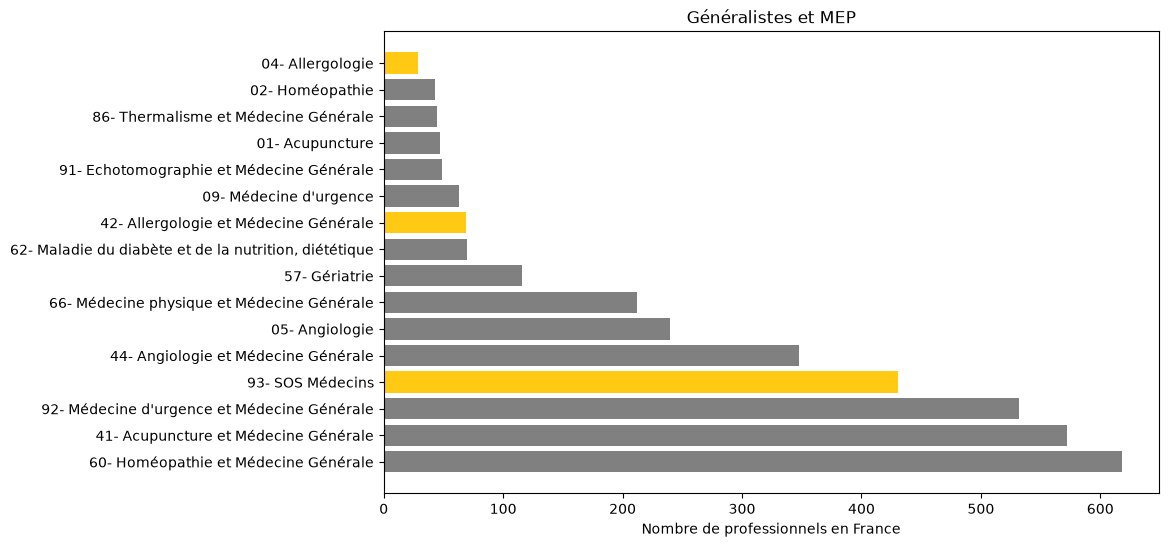

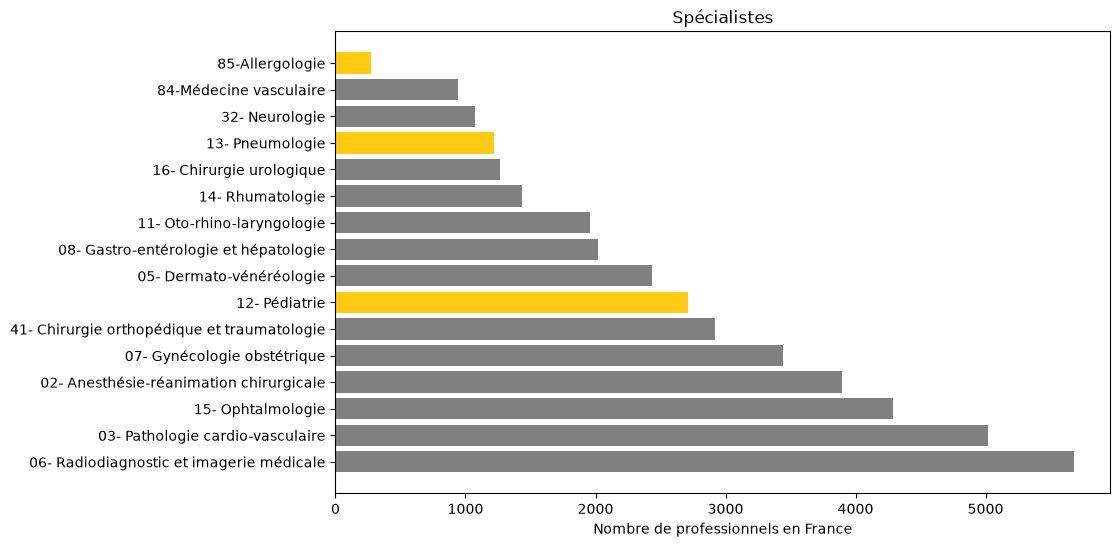

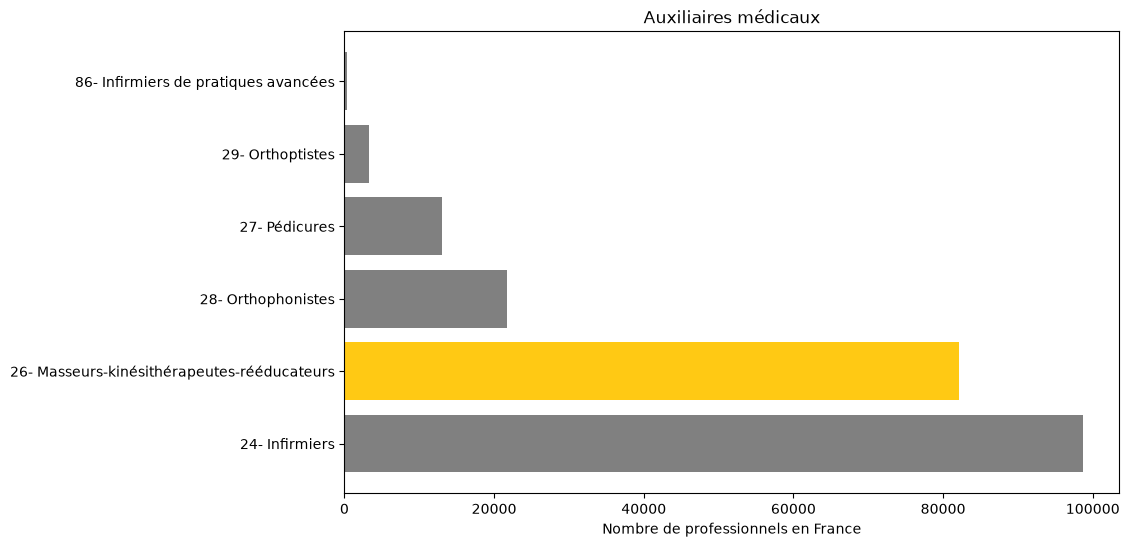

In [6]:
for i in range(3):   #parcoure les 3 onglets qui nous intéresse
    donnees = recap_ameli[recap_ameli['onglet'] == noms_onglets[i]]
    donnees = donnees.sort_values('nb_france', ascending=False)

    noms = []
    valeurs = []
    couleurs = []

    for nom in donnees.index:
        # on ne garde pas les totaux, ni la médecine générale (trop grande, écrase les autres professions)
        if nom == '01- Médecine générale':
            print('enlevé :', nom)
        # on garde les 15 plus grandes et les professions retenues
        elif len(noms) < 15 or nom in retenues:
            noms.append(nom)
            valeurs.append(donnees.loc[nom, 'nb_france'])
            if nom in retenues:
                couleurs.append('#ffc914')
            else:
                couleurs.append('grey')

    plt.figure(figsize=(10, 6))
    plt.barh(noms, valeurs, color=couleurs)
    plt.title(noms_onglets[i])
    plt.xlabel('Nombre de professionnels en France')
    plt.show()

Les professions retenues sont en jaune. J'ai retiré la médecine générale du premier graphique (51 775 médecins) car elle écrasait les autres barres.
Attention, certaines professions sont rares (17 départements sans allergologue). Une seule personne qui s'installe ou qui part peut faire beaucoup varier la densité.

## 4. Nettoyage

In [7]:
## [onglet, catégorie, fin du nom de mes colonnes]
professions = [[ameli_gen, '01- Médecine générale', 'generalistes'],
               [ameli_spe, '12- Pédiatrie', 'pediatres'],
               [ameli_spe, '13- Pneumologie', 'pneumologues'],
               [ameli_spe, '85-Allergologie', 'allergo_1'],
               [ameli_gen, '04- Allergologie', 'allergo_2'],
               [ameli_gen, '42- Allergologie et Médecine Générale', 'allergo_3'],
               [ameli_gen, '93- SOS Médecins', 'sos'],
               [ameli_aux, '26- Masseurs-kinésithérapeutes-rééducateurs', 'kines']]

# on part de la liste des départements avec leur population
lignes = ameli_gen[ameli_gen.iloc[:, 0] == '01- Médecine générale']
lignes = lignes[lignes['DEPARTEMENT'].str.contains('TOTAL') == False]
ameli_propre = lignes[['DEPARTEMENT', 'POPULATION FRANCAISE']].set_index('DEPARTEMENT')
ameli_propre.columns = ['population']

# pour chaque profession : le nombre et la densité donnés par Ameli
for onglet, categorie, nom in professions:
    lignes = onglet[onglet.iloc[:, 0] == categorie]
    lignes = lignes[lignes['DEPARTEMENT'].str.contains('TOTAL') == False]
    lignes = lignes.set_index('DEPARTEMENT')
    ameli_propre['nb_' + nom] = lignes['EFFECTIF']
    ameli_propre['densite_' + nom] = lignes['DENSITE /100 000 hab.']

ameli_propre.head()

,population,nb_generalistes,densite_generalistes,nb_pediatres,densite_pediatres,nb_pneumologues,densite_pneumologues,nb_allergo_1,densite_allergo_1,nb_allergo_2,densite_allergo_2,nb_allergo_3,densite_allergo_3,nb_sos,densite_sos,nb_kines,densite_kines
DEPARTEMENT,,,,,,,,,,,,,,,,,
01- Ain,688626,368,53.439748,9,6.878368,7,1.016517,1,0.145217,0,0.0,1,0.145217,0,0.000000,533,77.400505
02- Aisne,518817,311,59.944065,9,9.927529,16,3.083939,1,0.192746,0,0.0,3,0.578239,1,0.192746,294,56.667380
03- Allier,332599,221,66.446381,5,10.485258,5,1.503312,0,0.000000,0,0.0,1,0.300662,0,0.000000,351,105.532488
04- Alpes-Hte-Provence,169806,152,89.513916,10,39.306631,1,0.588907,1,0.588907,0,0.0,0,0.000000,1,0.588907,241,141.926669
05- Hautes-Alpes,142006,178,125.346816,0,0.000000,0,0.000000,0,0.000000,0,0.0,0,0.000000,0,0.000000,383,269.706914


In [8]:
# allergologues : on additionne les 3 catégories (nombre et densité)
ameli_propre['nb_allergologues'] = ameli_propre['nb_allergo_1'] + ameli_propre['nb_allergo_2'] + ameli_propre['nb_allergo_3']
ameli_propre['densite_allergologues'] = ameli_propre['densite_allergo_1'] + ameli_propre['densite_allergo_2'] + ameli_propre['densite_allergo_3']

# SOS Médecins présent ou non
ameli_propre['sos_present'] = ameli_propre['nb_sos'] > 0

# séparer le code et le nom du département
ameli_propre = ameli_propre.reset_index()
ameli_propre[['code_dep', 'nom_dep']] = ameli_propre['DEPARTEMENT'].str.split('- ', n=1, expand=True)

# DROM (code 97)
ameli_propre['est_drom'] = ameli_propre['code_dep'].str.startswith('97')

# on sélectionne et on range les colonnes
ameli_propre = ameli_propre[['code_dep', 'nom_dep', 'est_drom', 'population',
                             'nb_generalistes', 'nb_pediatres', 'nb_pneumologues', 'nb_allergologues', 'nb_kines', 'nb_sos',
                             'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines',
                             'sos_present']]

ameli_propre.head()

,code_dep,nom_dep,est_drom,population,nb_generalistes,nb_pediatres,nb_pneumologues,nb_allergologues,nb_kines,nb_sos,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,01,Ain,False,688626,368,9,7,2,533,0,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,02,Aisne,False,518817,311,9,16,4,294,1,59.944065,9.927529,3.083939,0.770985,56.667380,True
2,03,Allier,False,332599,221,5,5,1,351,0,66.446381,10.485258,1.503312,0.300662,105.532488,False
3,04,Alpes-Hte-Provence,False,169806,152,10,1,1,241,1,89.513916,39.306631,0.588907,0.588907,141.926669,True
4,05,Hautes-Alpes,False,142006,178,0,0,0,383,0,125.346816,0.000000,0.000000,0.000000,269.706914,False


nb_sos ne compte que les médecins déclarés SOS Médecins, c'est donc incomplet : 52 départements ont 0 alors qu'il existe 63 associations en France.
On garde nb_sos et sos_present (présent/absent) pour l'instant, à voir avec le groupe.

## 5. Inspection

In [9]:
print(ameli_propre.shape)
print(ameli_propre['est_drom'].value_counts())
print("cases vides :", ameli_propre.isna().sum().sum())

densites = ['densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines']
ameli_propre[densites].describe().round(1)

(101, 16)
est_drom
False    96
True      5
Name: count, dtype: int64
cases vides : 0


,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines
count,101.0,101.0,101.0,101.0,101.0
mean,73.4,19.3,1.6,0.5,114.5
std,18.1,12.9,0.9,0.4,48.8
min,8.8,0.0,0.0,0.0,19.4
25%,59.3,10.5,0.9,0.3,77.4
50%,74.8,17.5,1.5,0.4,102.0
75%,87.1,23.9,2.1,0.6,140.1
max,125.3,87.2,4.3,2.2,269.7


101 départements (96 en métropole et 5 DROM), pas de cases vides.

Les densités varient beaucoup selon les départements, par exemple de 8,8 à 125,3 généralistes pour 100 000 habitants.

## 6. Visualisation

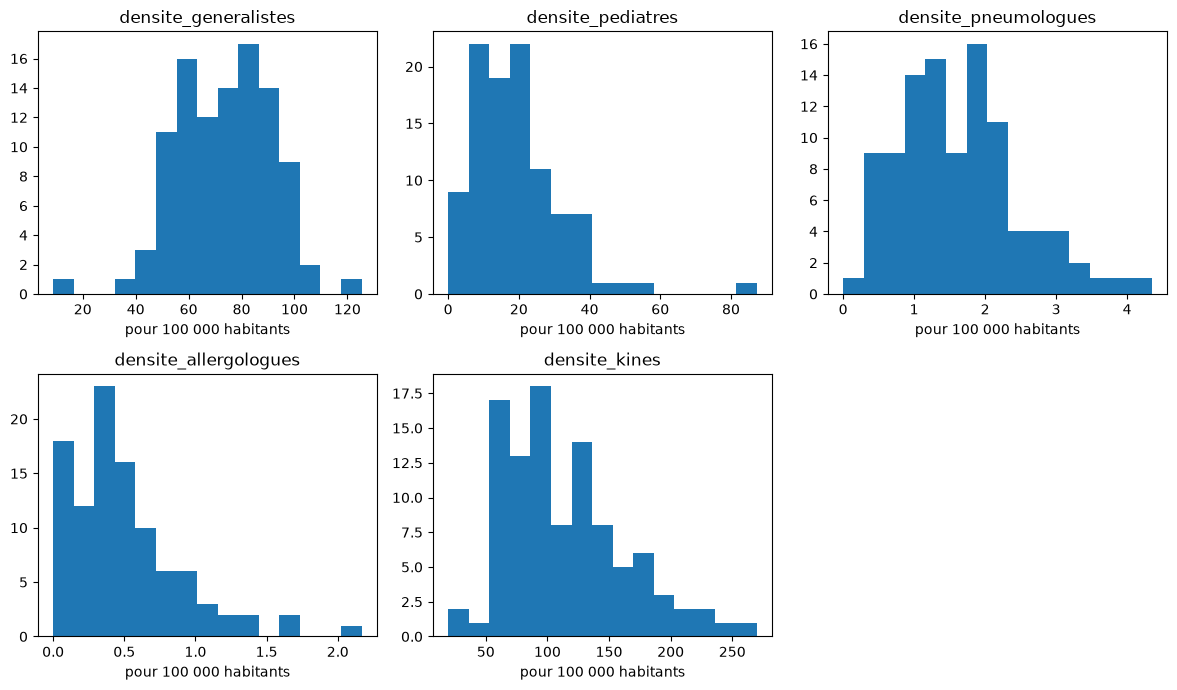

In [10]:
plt.figure(figsize=(12, 7))

for i in range(5):
    plt.subplot(2, 3, i + 1) #(le nombre de lignes, le nombre de colonnes, la case )
    plt.hist(ameli_propre[densites[i]], bins=15)
    plt.title(densites[i])
    plt.xlabel('pour 100 000 habitants')

plt.tight_layout()
plt.show()

Les généralistes et les kinés sont présents partout, avec de grandes différences entre départements. Les allergologues sont très peu nombreux, souvent proches de zéro.

In [11]:
# les 10 départements avec le moins de généralistes et les 10 avec le plus
print(ameli_propre.sort_values('densite_generalistes')[['nom_dep', 'densite_generalistes']].head(10))
print(ameli_propre.sort_values('densite_generalistes')[['nom_dep', 'densite_generalistes']].tail(10))

            nom_dep  densite_generalistes
100         Mayotte              8.807041
98           Guyane             32.836903
93   Seine-St-Denis             44.103662
17             Cher             45.972349
77   Seine-et-Marne             46.430997
28     Eure-et-Loir             47.789670
91          Essonne             48.454553
89            Yonne             50.433212
95       Val-d'Oise             50.870270
27             Eure             53.327397
                 nom_dep  densite_generalistes
16     Charente-Maritime             96.968310
29             Finistère             97.517939
67              Bas-Rhin             98.915946
12      Bouches-du-Rhône             99.319451
99               Réunion            100.538399
33               Gironde            100.718353
5        Alpes-Maritimes            101.685915
64  Pyrénées-Atlantiques            103.856860
73                Savoie            106.364433
4           Hautes-Alpes            125.346816


Les moins bien dotés : Mayotte, la Guyane, Ile-de-France (Seine-Saint-Denis, Essonne...) et une partie du Centre. Les mieux dotés : la montagne et le littoral, sans doute à cause des touristes.

## 7. Conclusion
Le tableau final a une ligne par département avec, pour chaque profession retenue, le nombre de professionnels et la densité donnée par Ameli, plus SOS Médecins. Je l'enregistre pour le réunir ensuite avec les autres fichiers grâce à code_dep.

In [12]:
ameli_propre.to_csv('../data/processed/ameli_2024_propre.csv', index=False)